# **Predicting Student Mental Health Score from Social Media Usage**






###**Problem Statement**
We're predicting a student's Mental_Health_Score (a continuous score from ~3 to ~10) using their social media habits, study time, sleep, physical activity, and stress level. This is a regression problem since the target is a number, not a category.




### *About Dataset*

- *Name* - Student_Social_Media_And_Mental_Health_Impact.csv
- *Rows* - 5,000 students,
- *Columns* - 13 columns
### *Covering*
- **demographics** (Age, Gender, Country),
- **platform usage **(Avg_Daily_Usage_Hours, Daily_Unlocks, Most_Used_Platform),
- **lifestyle** (Study_Hours, Sleep_Hours_Per_Night, Physical_Activity_Hours),
- **Stress_Level**

In [279]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from warnings import filterwarnings
filterwarnings('ignore')

In [280]:
df=pd.read_csv('Student Social Media And Mental Health Impact.csv')

In [281]:
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [282]:
df.shape

(5000, 13)

In [283]:
df.isna().sum()

,0
Age,0
Gender,0
Country,0
Academic_Level,0
Most_Used_Platform,0
Purpose_Of_Use,0
Avg_Daily_Usage_Hours,0
Daily_Unlocks,0
Study_Hours,0
Physical_Activity_Hours,0


***Insight***
- Zero null values

In [284]:
df.duplicated().sum()

np.int64(2)

In [285]:
df.drop_duplicates(inplace=True)

***Insight***
- 2 Duplicated value
- That has been removed

In [286]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4998 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      4998 non-null   int64  
 1   Gender                   4998 non-null   object 
 2   Country                  4998 non-null   object 
 3   Academic_Level           4998 non-null   object 
 4   Most_Used_Platform       4998 non-null   object 
 5   Purpose_Of_Use           4998 non-null   object 
 6   Avg_Daily_Usage_Hours    4998 non-null   float64
 7   Daily_Unlocks            4998 non-null   int64  
 8   Study_Hours              4998 non-null   float64
 9   Physical_Activity_Hours  4998 non-null   float64
 10  Sleep_Hours_Per_Night    4998 non-null   float64
 11  Stress_Level             4998 non-null   object 
 12  Mental_Health_Score      4998 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 546.7+ KB


In [287]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='object')

In [288]:
df.columns=df.columns.str.lower()

In [289]:
categorical_columns=[feature for feature in df.columns if df[feature].dtype =='O']
numerical_columns=[feature for feature in df.columns if df[feature].dtype!='O']
print(f"Categorical Columns = {categorical_columns}")
print(f"Numerical Columns = {numerical_columns}")

Categorical Columns = ['gender', 'country', 'academic_level', 'most_used_platform', 'purpose_of_use', 'stress_level']
Numerical Columns = ['age', 'avg_daily_usage_hours', 'daily_unlocks', 'study_hours', 'physical_activity_hours', 'sleep_hours_per_night', 'mental_health_score']


In [290]:
def get_unique_values(df):
    unique_data = {}

    for column in categorical_columns:
        unique_data[column] = df[column].unique().tolist()

    return unique_data

# INSIGHTS OF DATASET
- No null value
- No duplicated value
# Division of  Columns
##Categorical
1. gender
2. country
3. most_used_platform
4. academic_level
5. purpose_of_use
6. stress level
##Numerical
7. sleep_hour_per_night
8. physical_activity_hours
9. study_hours
10. daily_unlocks
11. avg_daily_usage_hours
12. age


# Target Feature
###***13. mental_health_score***

In [291]:
result = get_unique_values(df)
result

{'gender': ['Male', 'Female'],
 'country': ['Other',
  'Canada',
  'USA',
  'India',
  'Australia',
  'UK',
  'Germany',
  'Bangladesh',
  'Brazil',
  'Japan',
  'South Korea',
  'France',
  'Spain',
  'Italy',
  'Mexico',
  'Russia',
  'China',
  'Sweden',
  'Norway',
  'Denmark',
  'Netherlands',
  'Belgium',
  'Switzerland',
  'Austria',
  'Portugal',
  'Greece',
  'Ireland',
  'New Zealand',
  'Singapore',
  'Malaysia',
  'Thailand',
  'Vietnam',
  'Philippines',
  'Indonesia',
  'Taiwan',
  'Hong Kong',
  'Turkey',
  'Israel',
  'UAE',
  'Egypt',
  'Morocco',
  'South Africa',
  'Nigeria',
  'Kenya',
  'Ghana',
  'Argentina',
  'Chile',
  'Colombia',
  'Peru',
  'Venezuela',
  'Ecuador',
  'Uruguay',
  'Paraguay',
  'Bolivia',
  'Costa Rica',
  'Panama',
  'Jamaica',
  'Trinidad',
  'Bahamas',
  'Iceland',
  'Finland',
  'Poland',
  'Romania',
  'Hungary',
  'Czech Republic',
  'Slovakia',
  'Croatia',
  'Serbia',
  'Slovenia',
  'Bulgaria',
  'Estonia',
  'Latvia',
  'Lithuania',

# Categorical Data Analysis – Key Insights

### 1. Gender
- The `Gender` column contains **2 categories: Male and Female**.
- This variable can be used to compare smartphone usage, study hours, sleep patterns, and mental health scores across gender groups.
- The distribution of participants by gender should be examined to identify any imbalance.

### 2. Country
- The `Country` column contains **110 unique categories**, including India, USA, Canada, UK, Australia, and others.
- The dataset represents participants from a wide range of countries.
- The `Other` category represents an unspecified group of locations.
- Country-wise analysis can help identify differences in smartphone usage, social media preferences, and mental health scores.
- Countries with very few observations may need to be grouped for meaningful comparisons.

### 3. Academic Level
- The `Academic_Level` column contains **3 categories: Undergraduate, Graduate, and High School**.
- This feature represents the educational level of participants.
- It can be used to compare study hours, smartphone usage, and sleep duration across different academic groups.
- Further analysis can identify whether smartphone usage patterns differ by academic level.

### 4. Most Used Platform
- The `Most_Used_Platform` column contains **12 social media platforms**, including Instagram, Facebook, YouTube, TikTok, WhatsApp, and LinkedIn.
- This feature identifies the platform most frequently used by each participant.
- Platform-wise analysis can help determine which platforms are most popular.
- It can also be used to compare average daily usage hours, daily unlocks, and mental health scores across platforms.

### 5. Purpose of Use
- The `Purpose_Of_Use` column contains **4 categories: Networking, Education, Entertainment, and News**.
- This feature describes the primary purpose of smartphone or platform usage.
- It can help distinguish educational usage from entertainment and other activities.
- Comparing usage hours and study hours across these categories may reveal meaningful behavioral differences.

### 6. Stress Level
- The `Stress_Level` column contains **4 categories: Low, Medium, High, and Very High**.
- This is an **ordinal categorical variable**, because the categories have a meaningful order.
- Stress levels can be compared with smartphone usage, sleep duration, physical activity, and mental health scores.
- Further analysis can help determine whether participants reporting higher stress also show different smartphone usage or sleep patterns.

### 7. Data Preprocessing Recommendations
- Check the frequency of each category using `value_counts()`.
- Visualize categorical distributions using count plots or bar charts.
- Use One-Hot Encoding for nominal categorical variables such as Gender, Country, Most Used Platform, and Purpose of Use when appropriate for the model.
- Use Ordinal Encoding for Stress Level because its categories follow a natural order.
- Consider grouping infrequent countries into broader categories if necessary.

### 8. Conclusion
The dataset contains demographic, educational, behavioral, and psychological categorical features.

These variables can help investigate how smartphone usage patterns differ across gender, countries, academic levels, platforms, and purposes of use.

The Stress Level variable is particularly useful for examining associations between smartphone usage, sleep patterns, and mental health.

However, the unique-value output only identifies the available categories. **It does not show their frequencies or establish relationships between variables.** Additional visualizations and statistical analysis are required to draw meaningful conclusions.

In [292]:
df.describe()

,age,avg_daily_usage_hours,daily_unlocks,study_hours,physical_activity_hours,sleep_hours_per_night,mental_health_score
count,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000
mean,20.822129,5.078491,171.455582,3.008403,1.750760,6.634654,6.231152
std,1.736774,1.654097,42.859829,1.636831,0.668406,1.221561,1.278476
min,18.000000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.000000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.000000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.000000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.000000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


# Numerical feature – Key Insights

### 1. Dataset Overview
- The dataset contains **4,998 observations** with information about smartphone usage, study habits, physical activity, sleep duration, and mental health.
- The age of participants ranges from **18 to 24 years**, with an average age of **20.82 years**.
- All seven numerical columns have 4,998 non-null values, indicating no missing values in these columns.

### 2. Smartphone Usage Analysis
- The average daily smartphone usage is **5.08 hours**, with a minimum of 1 hour and a maximum of 8.8 hours.
- Approximately 25% of participants use their smartphones for **6.3 hours or more per day**.
- Participants unlock their smartphones approximately **171 times per day** on average.
- These statistics indicate frequent smartphone engagement among participants.

### 3. Study Hours Analysis
- The average study duration is **3.01 hours per day**.
- Study hours range from **0.3 to 8.3 hours**, showing considerable variation.
- The median study duration is **2.8 hours**, indicating that half of the participants study for approximately 2.8 hours or less daily.
- Further analysis is required to determine whether smartphone usage is associated with study duration.

### 4. Physical Activity Analysis
- Participants spend an average of **1.75 hours per day** on physical activity.
- The maximum recorded physical activity is **4.1 hours**.
- The minimum recorded value is **-0.4 hours**, which is invalid because time spent on physical activity cannot be negative.
- Negative values should be investigated and handled during data preprocessing.

### 5. Sleep Pattern Analysis
- The average sleep duration is **6.63 hours per night**.
- Sleep duration ranges from **3.6 to 9.9 hours**.
- Approximately 25% of participants sleep **5.6 hours or less** per night.
- The average sleep duration is below the generally recommended 7–9 hours for adults.
- The relationship between smartphone usage and sleep duration should be examined using correlation analysis.

### 6. Mental Health Analysis
- The average mental health score is **6.23**.
- Scores range from **3.6 to 9.4**, with a standard deviation of **1.28**.
- The median mental health score is **6.1**.
- The interpretation of these scores depends on how the mental health scale is defined.
- Correlation analysis can help identify whether smartphone usage, physical activity, and sleep duration are associated with mental health scores.

### 7. Data Quality Observations
- No missing values are indicated in the seven numerical columns.
- Negative values in the physical activity column represent a data-quality issue.
- Potential outliers should be investigated using box plots and the Interquartile Range (IQR) method.
- Duplicate records should also be checked before further analysis.

### 8. Conclusion
The descriptive analysis shows that participants spend a considerable amount of time using smartphones, with an average daily usage of approximately 5 hours and frequent daily unlocking. Average sleep duration is below the recommended range for adults, while study hours and physical activity vary across participants.

The dataset also contains invalid negative physical activity values that require preprocessing.

Further analysis using **correlation matrices, scatter plots, and regression models** is recommended to investigate relationships between smartphone usage, study habits, sleep duration, physical activity, and mental health.

**Note:** Descriptive statistics alone cannot establish causal relationships between smartphone usage and mental health or academic performance.

#EDA-Exploratory Data Analysis


#4.1 - Distribution of target (mental_health_score)

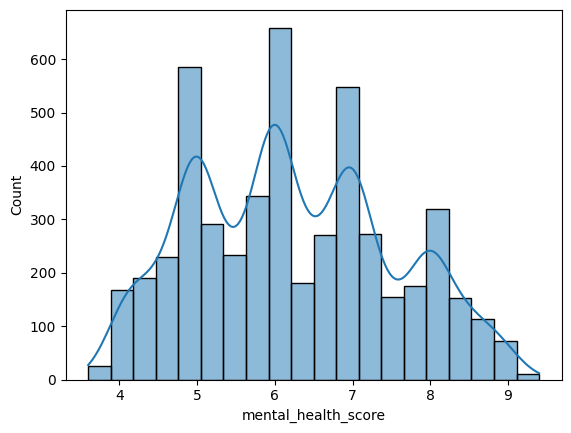

In [293]:
sns.histplot(df['mental_health_score'],bins=20,kde=True)
plt.show()

# 4.2 - Heatmap and correlation
+ve correlation mean -> when one goes up another goes up with it
-ve correlation mean-> one goes up and another goes down

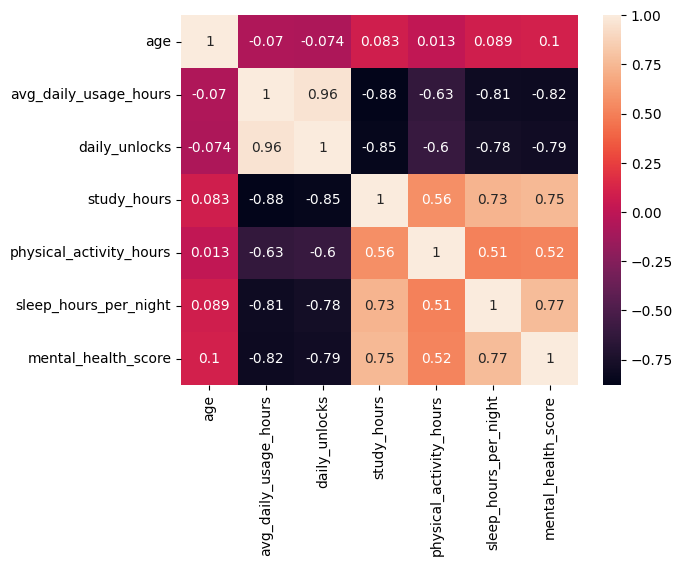

In [294]:
sns.heatmap(df.corr(numeric_only=True),annot=True)
plt.show()

# 4.3 - Stress Level vs Mental Health

In [295]:
df['stress_level'].unique()

array(['Medium', 'Low', 'Very High', 'High'], dtype=object)

In [296]:
order=['Low', 'Medium', 'High', 'Very High']

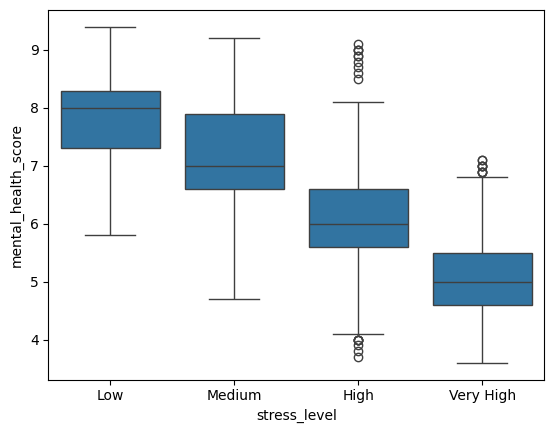

In [297]:
sns.boxplot(x='stress_level',y='mental_health_score',data=df,order=order)
plt.show()

#4.4 - Avg daily usage of phone per hours vs Mental Health

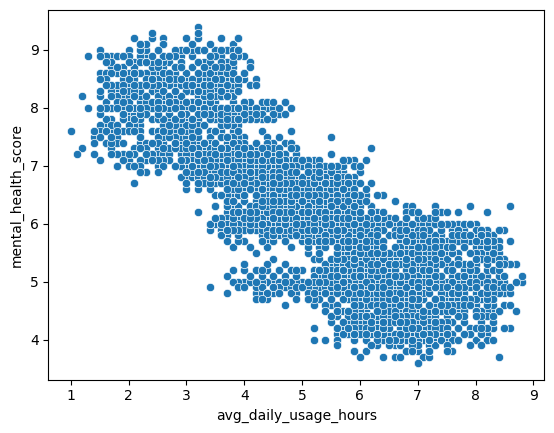

In [298]:
sns.scatterplot(data=df,x='avg_daily_usage_hours',y='mental_health_score')
plt.show()

#4.5 Sleep hours vs Mental Health

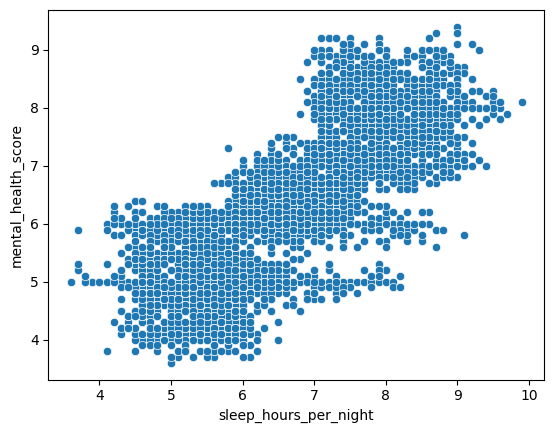

In [299]:
sns.scatterplot(data=df,x='sleep_hours_per_night',y='mental_health_score')
plt.show()

#4.6 Most used platform


In [300]:
df['most_used_platform'].value_counts()

,count
most_used_platform,
Instagram,1130
TikTok,918
Facebook,719
LinkedIn,522
YouTube,491
Twitter,462
Snapchat,419
WhatsApp,175
LINE,50


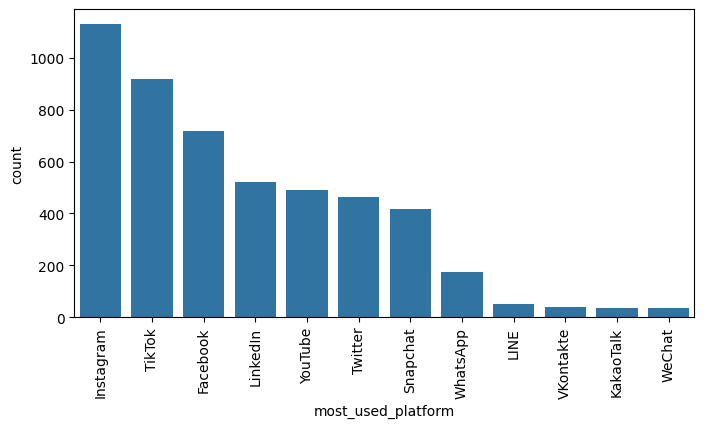

In [301]:
plt.figure(figsize=(8, 4))
sns.countplot(x=df['most_used_platform'], order=df['most_used_platform'].value_counts().index)
plt.xticks(rotation=90)
plt.show()

#4.7 Checking Outliers


In [302]:
num_features = df.select_dtypes(include='number') #int64 or float64
Q1  = num_features.quantile(0.25)
Q3  = num_features.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (num_features < lower_bound) | (num_features > upper_bound)
print(outliers.sum())

age                         0
avg_daily_usage_hours       0
daily_unlocks               0
study_hours                 2
physical_activity_hours    22
sleep_hours_per_night       0
mental_health_score         0
dtype: int64


# 5 Data Cleaning


In [303]:
#. Converting negative or unrealitstic value to realistic value
df['physical_activity_hours'] = df['physical_activity_hours'].clip(lower=0)

#6. Skewness

***What skewness is:*** a measure of how lopsided a numeric column's distribution is. A value near 0 means roughly symmetric (bell-shaped); a large positive or negative value means the data leans heavily to one side, with a long tail.

***Why it matters:*** models like Linear Regression assume features are roughly well-behaved. A heavily skewed column (think: a long tail of extreme values) can quietly drag the model's predictions in that direction. Tree-based models like Random Forest don't care about skew — but since we're also training a Linear Regression baseline, it's worth fixing.

## near to 0 -> Centralized (0.01, 0.002)
## negative -> Left Skewed (-1.56)
## poistive (greater than 0) -> Right Skewed (1.256)

In [304]:
skewness=num_features.skew()
skewness

,0
age,0.155008
avg_daily_usage_hours,0.005575
daily_unlocks,0.002309
study_hours,0.436125
physical_activity_hours,0.040623
sleep_hours_per_night,0.123919
mental_health_score,0.207086


#7. Feature Engineering

One meaningful engineered feature here: grouping Country.

Country has 111 unique values in this dataset — one-hot encoding that directly would add 110+ mostly-empty columns, which hurts the model far more than it helps (this is called high cardinality).
Dropping Country entirely throws away real signal — a student's country genuinely correlates with things like internet access, culture, and sleep norms.
The fix: keep the top 10 most frequent countries as their own category, and bucket everything else into "Other". We keep the signal that matters and lose the noise that doesn't.

In [305]:
top_countries=df['country'].value_counts().index[:10].tolist()
top_countries

['Other',
 'India',
 'USA',
 'Canada',
 'Australia',
 'UK',
 'Germany',
 'Mexico',
 'Turkey',
 'France']

In [306]:
def group_countries(country):
  if country in top_countries:
    return country
  else:
    return 'Other'

df['grouped_country'] = df['country'].apply(group_countries)


df['grouped_country'].value_counts()

,count
grouped_country,
Other,3231
India,389
USA,354
Canada,230
Australia,198
UK,185
Germany,136
Mexico,94
Turkey,94


#8. X and Y split


In [307]:
skewed_feature = ['physical_activity_hours']
numeric_feature = ['age', 'avg_daily_usage_hours', 'daily_unlocks', 'sleep_hours_per_night']

ordinal = ['stress_level']
nominal = ['gender', 'most_used_platform', 'academic_level', 'purpose_of_use', 'grouped_country']

# Combine all unique feature columns
final_feature_columns = skewed_feature + numeric_feature + ordinal + nominal
target_feature = ['mental_health_score']

X = df[final_feature_columns]
y = df[target_feature]

#9. Creating Pipeline

In [308]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
import numpy as np

# Redefining the pipelines with the correct list of (name, transformer) tuples
skew_pipeline = Pipeline(
    steps=[
        ('log_transform', FunctionTransformer(np.log1p)),
        ('scaler', StandardScaler())
    ]
)

numerical_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='mean')),
        ('scaler', StandardScaler())
    ]
)

ordinal_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ordinal_encoder', OrdinalEncoder())
    ]
)

nominal_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('one_hot_encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

# Creating and fitting the ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('skew', skew_pipeline, skewed_feature),
        ('num', numerical_pipeline, numeric_feature),
        ('ord', ordinal_pipeline, ordinal),
        ('nom', nominal_pipeline, nominal)
    ]
)

X = preprocessor.fit_transform(X)

# 10 Train Test split


In [309]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

#11 Model Training

In [ ]:
#clearpip install catboost

In [311]:
def evaluate_model(true, predicted):
    mae = mean_absolute_error(true, predicted)
    mse = mean_squared_error(true, predicted)
    rmse = np.sqrt(mean_squared_error(true, predicted))
    r2_square = r2_score(true, predicted)
    return mae, rmse, r2_square

In [312]:
from sklearn.linear_model import LinearRegression,Lasso,Ridge,ElasticNet
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.ensemble import BaggingRegressor
from sklearn.ensemble import GradientBoostingRegressor
models={

        'LinearRegression':LinearRegression(),
        'Lasso':Lasso(),
        'Ridge':Ridge(),
        'KNeighborsRegressor':KNeighborsRegressor(),
        'ElasticNet':ElasticNet(),
        'DecisionTreeRegressor':DecisionTreeRegressor(),
        'RandomForestRegressor':RandomForestRegressor(),
        'XGBRegressor':XGBRegressor(),
        'CatBoostRegressor':CatBoostRegressor(verbose=False),
        'AdaBoostRegressor':AdaBoostRegressor(),
        'BaggingRegressor':BaggingRegressor(),
        'GradientBoostingRegressor':GradientBoostingRegressor(),
}
model_list = []
r2_list =[]

In [314]:
from sklearn.metrics import mean_absolute_error

for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train, y_train) # Train model

    # Make predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Evaluate Train and Test dataset
    model_train_mae , model_train_rmse, model_train_r2 = evaluate_model(y_train, y_train_pred)

    model_test_mae , model_test_rmse, model_test_r2 = evaluate_model(y_test, y_test_pred)


    print(list(models.keys())[i])
    model_list.append(list(models.keys())[i])

    print('Model performance for Training set')
    print("- Root Mean Squared Error: {:.4f}".format(model_train_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_train_mae))
    print("- R2 Score: {:.4f}".format(model_train_r2))

    print('----------------------------------')

    print('Model performance for Test set')
    print("- Root Mean Squared Error: {:.4f}".format(model_test_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_test_mae))
    print("- R2 Score: {:.4f}".format(model_test_r2))
    r2_list.append(model_test_r2)

    print('='*35)
    print('\n')

LinearRegression
Model performance for Training set
- Root Mean Squared Error: 0.6681
- Mean Absolute Error: 0.5236
- R2 Score: 0.7176
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 0.6882
- Mean Absolute Error: 0.5468
- R2 Score: 0.7304


Lasso
Model performance for Training set
- Root Mean Squared Error: 1.2458
- Mean Absolute Error: 1.0330
- R2 Score: 0.0182
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 1.3147
- Mean Absolute Error: 1.1046
- R2 Score: 0.0159


Ridge
Model performance for Training set
- Root Mean Squared Error: 0.6681
- Mean Absolute Error: 0.5237
- R2 Score: 0.7176
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 0.6881
- Mean Absolute Error: 0.5467
- R2 Score: 0.7304


KNeighborsRegressor
Model performance for Training set
- Root Mean Squared Error: 0.4174
- Mean Absolute Error: 0.3006
- R2 Score: 0.8898
--------------------------

In [315]:
lin_model = LinearRegression(fit_intercept=True)
lin_model = lin_model.fit(X_train, y_train)
y_pred = lin_model.predict(X_test)
score = r2_score(y_test, y_pred)*100
print(" Accuracy of the model is %.2f" %score)

 Accuracy of the model is 73.04


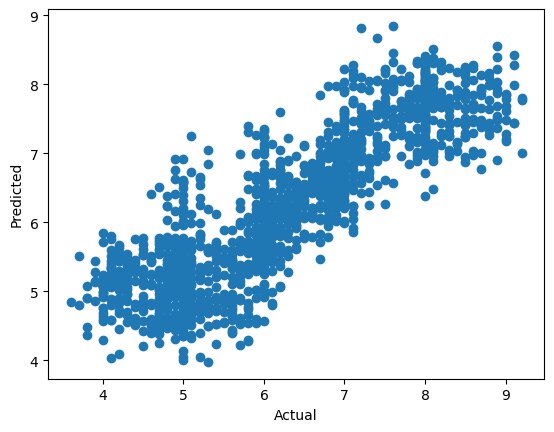

In [316]:
plt.scatter(y_test,y_pred);
plt.xlabel('Actual');
plt.ylabel('Predicted');

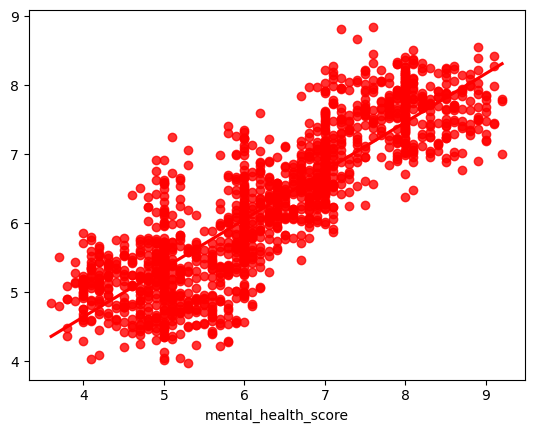

In [317]:
sns.regplot(x=y_test,y=y_pred,ci=None,color ='red');